In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

DATA = "../data/raw/"
CAP, WIN, SEED = 125, 10, 42

cols = (
    ["unit", "cycle"]
    + [f"op{i}" for i in range(1, 4)]
    + [f"s{i}" for i in range(1, 22)]
)

train = pd.read_csv(DATA + "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(DATA + "test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul = pd.read_csv(DATA + "RUL_FD001.txt", header=None, names=["RUL"])

# Training labels: last cycle minus current cycle, capped at 125
train["RUL"] = (train.groupby("unit")["cycle"].transform("max") - train["cycle"]).clip(upper=CAP)

# Sensor selection: drop (near-)constant sensors
sensor_cols = [c for c in cols if c.startswith("s")]
std = train[sensor_cols].std()
keep_sensors = [s for s in sensor_cols if std[s] >= 0.01]
print(len(keep_sensors), "sensors kept:", keep_sensors)

14 sensors kept: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [2]:
def add_features(df, sensors, win=WIN):
    out = df.copy()
    g = df.groupby("unit")
    for s in sensors:
        out[f"{s}_mean"] = g[s].transform(lambda x: x.rolling(win, min_periods=1).mean())
        out[f"{s}_std"] = g[s].transform(lambda x: x.rolling(win, min_periods=1).std()).fillna(0.0)
    return out

train_f = add_features(train, keep_sensors)
test_f = add_features(test, keep_sensors)

feature_cols = (
    keep_sensors
    + [f"{s}_mean" for s in keep_sensors]
    + [f"{s}_std" for s in keep_sensors]
)
print("number of features:", len(feature_cols))

X = train_f[feature_cols]
y = train_f["RUL"]
groups = train_f["unit"]
print(X.shape)

number of features: 42
(20631, 42)


In [3]:
def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_pred) - np.asarray(y_true)) ** 2)))

def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

# True test labels, capped to match training
y_test_true = np.minimum(rul["RUL"].values, CAP)

median_pred = np.full(len(y_test_true), y.median(), dtype=float)
print(f"Median baseline | RMSE {rmse(y_test_true, median_pred):.2f}")

Median baseline | RMSE 49.20


In [4]:
def make_model():
    return XGBRegressor(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=SEED,
        n_jobs=-1,
    )

cv_scores = []
for fold, (tr_idx, va_idx) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
    m = make_model().fit(X.iloc[tr_idx], y.iloc[tr_idx])
    score = rmse(y.iloc[va_idx], m.predict(X.iloc[va_idx]))
    cv_scores.append(score)
    print(f"fold {fold}: RMSE {score:.2f}")

print(f"Grouped 5-fold CV RMSE: {np.mean(cv_scores):.2f} +/- {np.std(cv_scores):.2f}")

fold 1: RMSE 19.92
fold 2: RMSE 18.38
fold 3: RMSE 19.36
fold 4: RMSE 18.50
fold 5: RMSE 18.60
Grouped 5-fold CV RMSE: 18.95 +/- 0.59


In [5]:
model = make_model().fit(X, y)

# Official evaluation: only the LAST observed cycle of each test engine
last_rows = test_f.groupby("unit").tail(1)
preds = np.clip(model.predict(last_rows[feature_cols]), 0, CAP)

test_rmse = rmse(y_test_true, preds)
test_nasa = nasa_score(y_test_true, preds)
print(f"XGBoost test | RMSE {test_rmse:.2f} | NASA score {test_nasa:.0f}")

XGBoost test | RMSE 18.55 | NASA score 1357


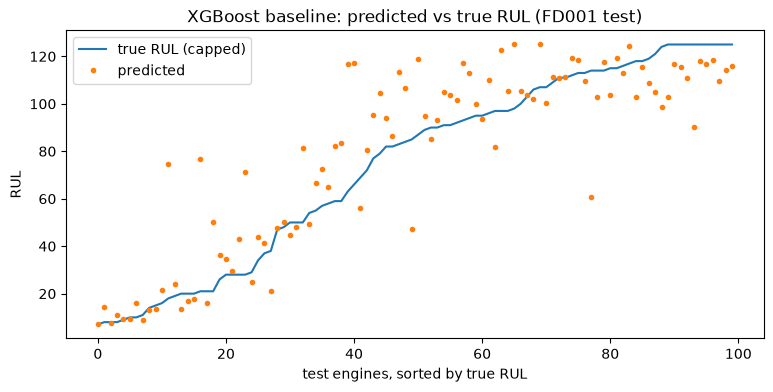

In [6]:
order = np.argsort(y_test_true)
plt.figure(figsize=(9, 4))
plt.plot(y_test_true[order], label="true RUL (capped)")
plt.plot(preds[order], ".", label="predicted")
plt.xlabel("test engines, sorted by true RUL")
plt.ylabel("RUL")
plt.title("XGBoost baseline: predicted vs true RUL (FD001 test)")
plt.legend()
plt.show()

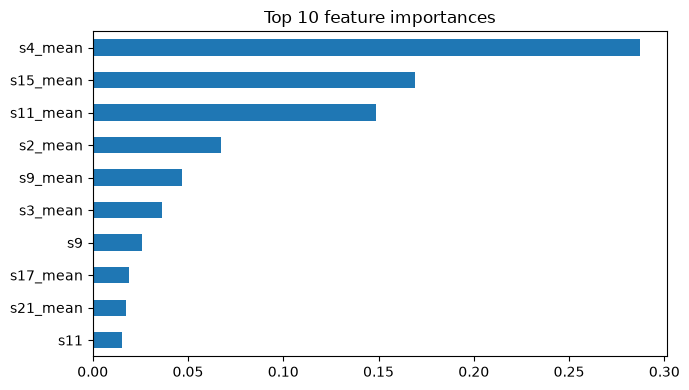

In [7]:
imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)
imp[::-1].plot.barh(figsize=(7, 4), title="Top 10 feature importances")
plt.tight_layout()
plt.show()

| Model | CV RMSE | Test RMSE | NASA score |
|---|---|---|---|
| Median baseline | n/a | RMSE 49.20 | n/a |
| XGBoost + rolling features (window 10) | XGBoost test | RMSE 18.55  |  NASA score 1357 |